# Simulate TOLIMAN data

This notebook runs the `toliman_sim` simulator on a JSON config. It is the notebook equivalent of

```bash
python -m toliman_sim configs/example.json
```

**How to use it**

1. Select the **Python (toliman_data)** kernel.
2. Set `CONFIG` below to the config you want to simulate.
3. Run all cells.

Everything about the simulation lives in the config:

| Config section | What it controls |
| --- | --- |
| `optics` | Pupil and Zernike aberrations |
| `source` | Alpha Cen A and B: separation, position angle, spectra |
| `detector` | Detector effects |
| `noise` | Poisson and read noise |
| `observations` | How many observations, and which parameters to draw at random for each |
| `output` | Where to write the results, and in which format |

See DEVELOPMENT.md for every option.

**Where the output goes:** `output.directory` in the config, **relative to the config file**. For `configs/example.json` that is `simulated_data/sim_run_0001/` at the top of the repository.

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

from toliman_sim import load_config, simulate, save

CONFIG = Path("../configs/example.json")  # relative to this notebook

## Load the config

`load_config` returns a plain dictionary. You can change it here before simulating without editing the file. For example, uncomment the lines below to make more observations, or to switch off read noise.

In [2]:
config = load_config(CONFIG)

# config["observations"]["n_observations"] = 50
# config["noise"]["read_noise"] = False
# config["observations"]["parameters"]["separation_arcsec"] = {"std": 0.05}

print("run_id:          ", config["run_id"])
print("observations:    ", config["observations"]["n_observations"])
print("drawn parameters:", json.dumps({k: v for k, v in config["observations"]["parameters"].items() if not k.startswith("_")}, indent=2))
print("noise:           ", {k: v for k, v in config["noise"].items() if not k.startswith("_")})
print("output:          ", config["output"]["format"], "->", (CONFIG.parent / config["output"]["directory"]).resolve())

run_id:           sim_run_0001
observations:     10
drawn parameters: {
  "x_position_arcsec": {
    "std": 0.5
  },
  "y_position_arcsec": {
    "std": 0.5
  },
  "separation_arcsec": {
    "std": 0.01
  },
  "position_angle_deg": {
    "std": 0.1
  },
  "zernike_coefficients_m": {
    "mean": 0.0,
    "std": [
      5e-09,
      5e-09,
      5e-09,
      2e-09,
      2e-09,
      2e-09,
      2e-09
    ]
  }
}
noise:            {'poisson': True, 'read_noise': True, 'read_noise_electrons': 5.0}
output:           npy -> /Users/mlan9526/Desktop/repos/toliman_data/simulated_data/sim_run_0001


## Simulate

For each observation the simulator:

1. draws the parameters listed in `observations.parameters` from `jax.random`, using a key derived from `seed`;
2. models the noiseless image with dLuxToliman;
3. adds Poisson and read noise.

The first observation is slower because JAX compiles the model.

In [3]:
start = time.time()
result = simulate(config)
print(f"Simulated {len(result['data'])} observations in {time.time() - start:.1f} s (seed {result['seed']})")
print("data:    ", result["data"].shape, "photoelectrons")
print("expected:", result["expected"].shape)

Simulated 10 observations in 5.8 s (seed 42)
data:     (10, 128, 128) photoelectrons
expected: (10, 128, 128)


## Look at the results

The top row shows noisy observations and the bottom row the matching noiseless images. The table lists the true parameters of each observation.

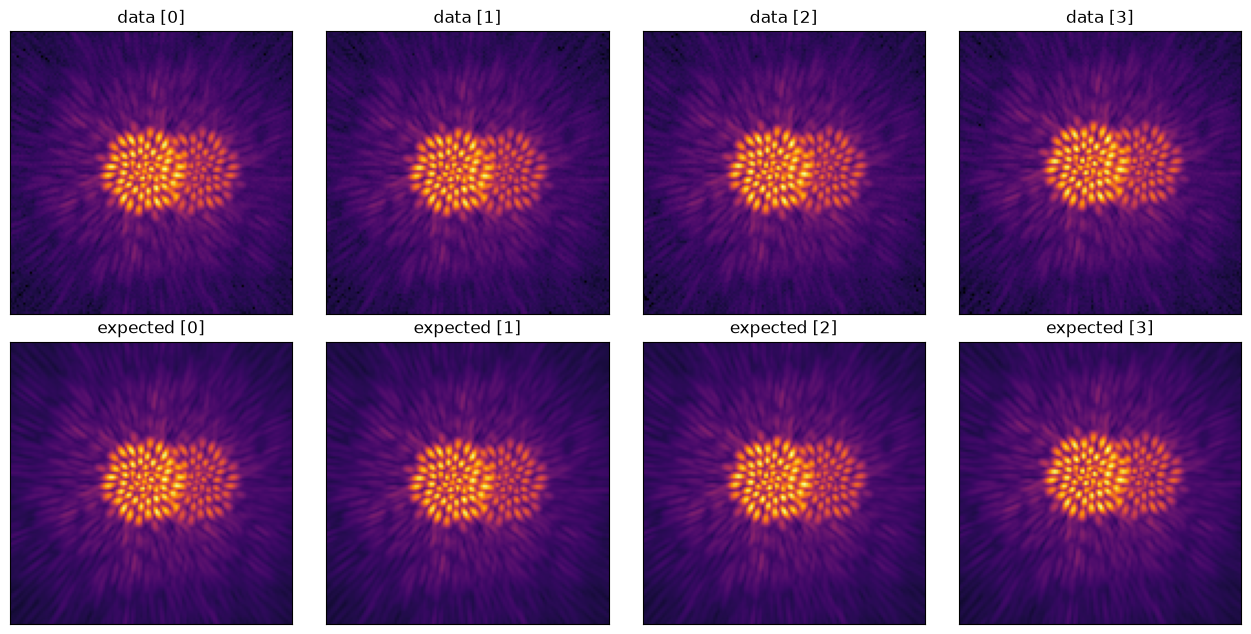

In [4]:
n_show = min(4, len(result["data"]))
fig, axes = plt.subplots(2, n_show, figsize=(3.2 * n_show, 6.4), squeeze=False)
for i in range(n_show):
    for row, (name, images) in enumerate([("data", result["data"]), ("expected", result["expected"])]):
        ax = axes[row, i]
        ax.imshow(images[i], origin="lower", cmap="inferno", norm=PowerNorm(0.3, vmin=0))
        ax.set_title(f"{name} [{i}]")
        ax.set_xticks([]), ax.set_yticks([])
plt.tight_layout()
plt.show()

In [5]:
truth = result["truth"]
scalars = [name for name, values in truth.items() if values.ndim == 1]
print(" obs  " + "  ".join(f"{name:>20}" for name in scalars))
for i in range(len(result["data"])):
    print(f"{i:4d}  " + "  ".join(f"{truth[name][i]:20.6g}" for name in scalars))
if "zernike_coefficients_m" in truth:
    print("\nzernike_coefficients_m [nm]:\n", np.round(truth["zernike_coefficients_m"] * 1e9, 2))

 obs     x_position_arcsec     y_position_arcsec     separation_arcsec    position_angle_deg       exposure_time_s
   0               1.09705              0.242197               9.99566               89.9918                   0.1
   1             -0.465425             0.0460635               9.99257               89.9181                   0.1
   2             0.0646986              0.433366                10.008               89.8522                   0.1
   3             0.0650269               1.30021               9.99521               89.9846                   0.1
   4            -0.0176665             0.0510425                9.9982               89.9235                   0.1
   5              0.418365                0.1637               10.0216                89.985                   0.1
   6              0.172323               0.35319               10.0008               89.8967                   0.1
   7              0.457872              0.418834               9.99912          

## Save

This writes the outputs to `output.directory`. With the default `npy` format you get:

- `{run_id}_data.npy`: the noisy observations, shape `(n_observations, ny, nx)`.
- `{run_id}_expected.npy`: the noiseless images.
- `{run_id}_truth.npz`: the true parameters.
- `config.json`: the config used, including the seed.

Existing files are not replaced unless `OVERWRITE = True`.

In [ ]:
OVERWRITE = False
path = save(result, config, overwrite=OVERWRITE)
print("Wrote", path.resolve())

Wrote /Users/mlan9526/Desktop/repos/toliman_data/simulated_data/sim_run_0001/sim_run_0001_data.npy


## Loading the saved data later

In [9]:
directory = path.parent
data = np.load(directory / f"{config['run_id']}_data.npy")
truth = np.load(directory / f"{config['run_id']}_truth.npz")
print(data.shape, sorted(truth.files))

(10, 128, 128) ['exposure_time_s', 'pixel_scale_arcsec', 'position_angle_deg', 'seed', 'separation_arcsec', 'x_position_arcsec', 'y_position_arcsec', 'zernike_coefficients_m']
